# 02 — Preprocessing QC

This notebook runs the preprocessing pipeline stage by stage on a single
subject and produces visual QC at each step. The purpose is to *see* what
each stage actually does to the data before we scale to the development
subset.

**Goal:** validate each preprocessing stage with plots, then run the full
pipeline end-to-end and save a cleaned derivative.

**What we'll do:**
1. Load raw and high-pass filter, comparing PSDs
2. Detect bad channels via a log-variance histogram
3. Average reference
4. Build the ICA training copy (1–100 Hz, 250 Hz)
5. Fit Picard-extended ICA and cache it to disk
6. Classify components with ICLabel and inspect the category breakdown
7. Visually inspect component topographies
8. Apply ICA and compare before/after PSDs and amplitudes
9. Low-pass, interpolate, downsample; save derivative
10. Run the full pipeline via `preprocess_subject` for a headless check

**Reference:** the MNE-ICALabel tutorial
(`mne-icalabel` docs, *Usage*) specifies 1–100 Hz filtering and 250 Hz
sampling for ICLabel input. Pion-Tonachini et al. (2019) trained ICLabel
on extended-Infomax / Picard decompositions from average-referenced EEG
in this band.

In [1]:
# Setup: add src/ to path so we can import the eeg_state package.

import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = REPO_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import json
import numpy as np
import matplotlib.pyplot as plt
import mne

from eeg_state import config
from eeg_state.io import load_raw
from eeg_state import preprocessing as pp

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

SUBJECT = "sub-04"
CACHE = config.DATA_DERIV / SUBJECT / "cache"
CACHE.mkdir(parents=True, exist_ok=True)

print(f"Repo root: {REPO_ROOT}")
print(f"Subject:   {SUBJECT}")
print(f"Cache:     {CACHE}")

Repo root: d:\Research\eeg-neural-state-dynamics
Subject:   sub-04
Cache:     D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-04\cache


## 1. Load raw and inspect PSD before filtering

We load the raw BrainVision file, attach the CapTrak montage, and plot the
power spectral density (PSD) before any filtering. This is the baseline
against which every later stage is compared.

The PSD is the distribution of signal power across frequencies. It shows
us (a) the characteristic 1/f slope of EEG, (b) any 50 Hz line-noise peak,
and (c) low-frequency drift below 1 Hz.

sfreq: 1000.0 Hz
channels: 63
duration: 1196.5 s
reference: None
Plotting power spectral density (dB=True).


C:\Users\DELL\AppData\Local\Temp\ipykernel_8188\2192019109.py:11: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


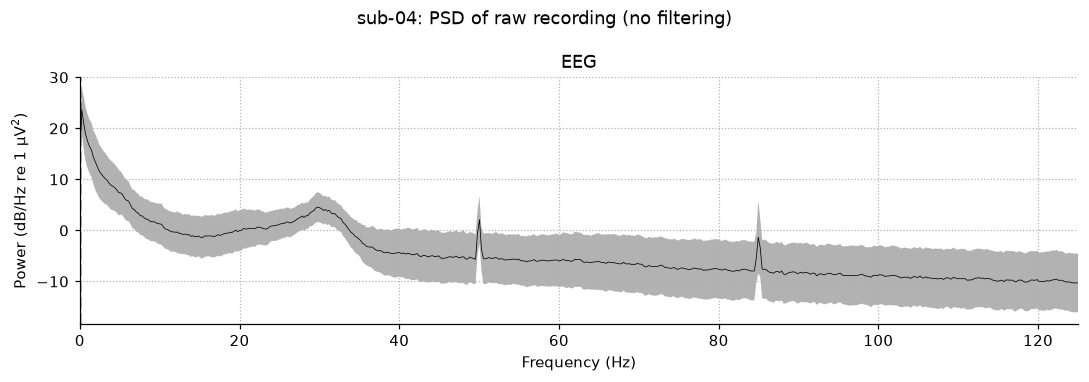

In [2]:
raw = load_raw(SUBJECT, preload=True)
print(f"sfreq: {raw.info['sfreq']} Hz")
print(f"channels: {len(raw.ch_names)}")
print(f"duration: {raw.times[-1]:.1f} s")
print(f"reference: {raw.info['description'] if 'description' in raw.info else 'FCz (from BIDS sidecar)'}")

fig = raw.compute_psd(fmax=125, n_fft=4096, verbose="ERROR").plot(
    average=True, show=False,
)
fig.suptitle(f"{SUBJECT}: PSD of raw recording (no filtering)")
plt.tight_layout()
plt.show()

## 2. High-pass filter at 1 Hz

A 1 Hz zero-phase FIR high-pass is applied. Justification: Winkler et al.
(2015, *Psychophysiology*) show that a 1 Hz high-pass is essential before
ICA to prevent slow drift from dominating the decomposition. Values above
1 Hz distort ERP waveforms; values below 1 Hz leave enough drift to
destabilize ICA.

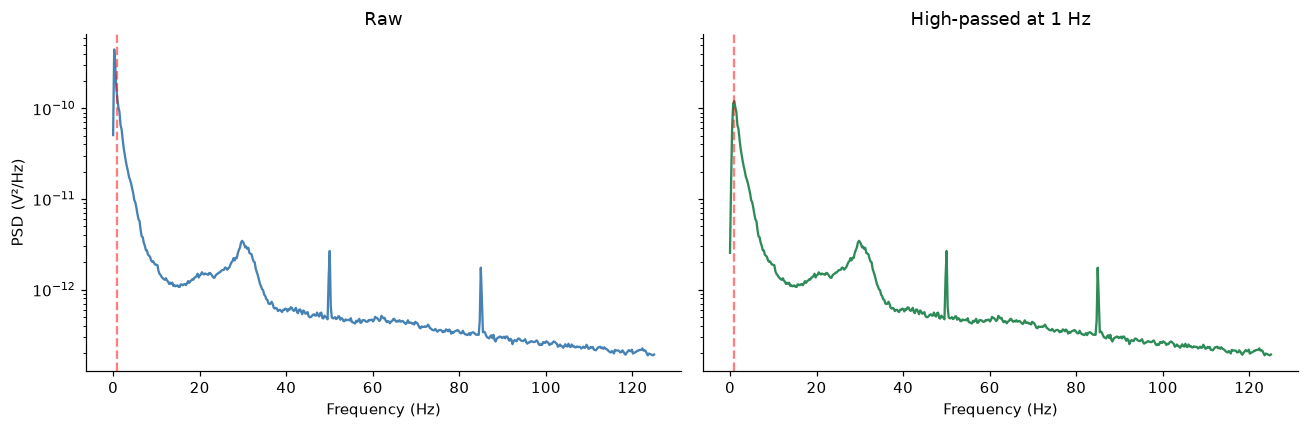

Check: at the red line (1 Hz), power should drop sharply in the right panel.


In [3]:
raw_hp = pp.highpass(raw)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

psd_raw = raw.compute_psd(fmax=125, n_fft=4096, verbose="ERROR")
psd_hp = raw_hp.compute_psd(fmax=125, n_fft=4096, verbose="ERROR")

axes[0].semilogy(psd_raw.freqs, psd_raw.get_data().mean(axis=0), color="steelblue")
axes[0].set_title("Raw")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("PSD (V²/Hz)")
axes[0].axvline(1.0, color="red", linestyle="--", alpha=0.5)

axes[1].semilogy(psd_hp.freqs, psd_hp.get_data().mean(axis=0), color="seagreen")
axes[1].set_title("High-passed at 1 Hz")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].axvline(1.0, color="red", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

print("Check: at the red line (1 Hz), power should drop sharply in the right panel.")

## 3. Bad-channel detection

A robust MAD-based z-score on log-variance flags channels whose broadband
amplitude is anomalous. Threshold 4.0 (config).

The histogram below is the key diagnostic: if it's tight and symmetric
with no visible tail, zero bad channels is the correct answer — not a
threshold problem. If it has an obvious outlier, the flagging should pick
it up.

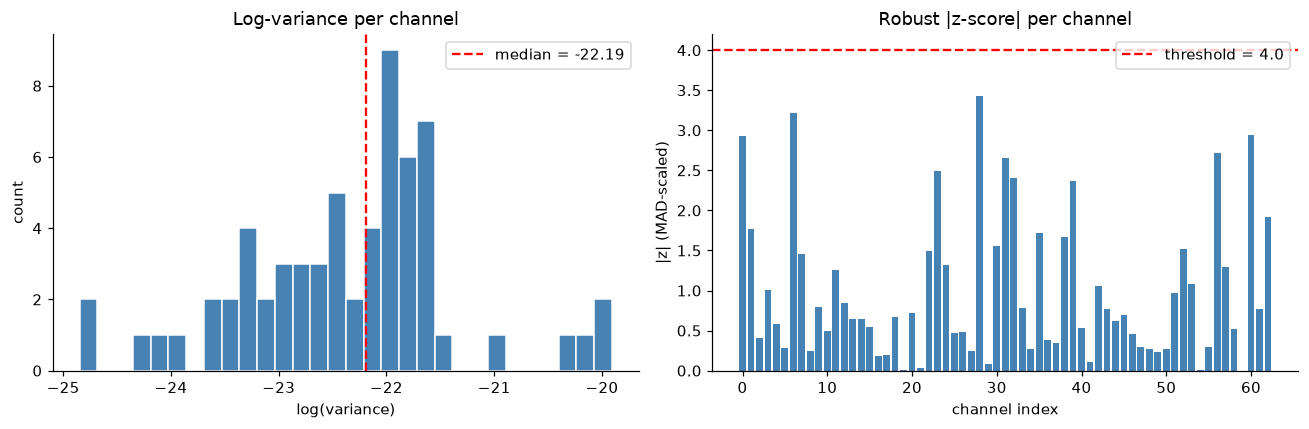

Max |z|: 3.429
Bad channels flagged: []


In [4]:
eeg = raw_hp.copy().pick("eeg")
log_var = np.log(np.var(eeg.get_data(), axis=1))
median = float(np.median(log_var))
mad = float(np.median(np.abs(log_var - median)))
z = (log_var - median) / (1.4826 * mad)

bad_channels = pp.detect_bad_channels(raw_hp)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(log_var, bins=30, color="steelblue", edgecolor="white")
axes[0].axvline(median, color="red", linestyle="--", label=f"median = {median:.2f}")
axes[0].set_title("Log-variance per channel")
axes[0].set_xlabel("log(variance)")
axes[0].set_ylabel("count")
axes[0].legend()

axes[1].bar(np.arange(len(z)), np.abs(z), color="steelblue")
axes[1].axhline(config.BAD_CHANNEL_Z_THRESHOLD, color="red", linestyle="--",
                label=f"threshold = {config.BAD_CHANNEL_Z_THRESHOLD}")
axes[1].set_title("Robust |z-score| per channel")
axes[1].set_xlabel("channel index")
axes[1].set_ylabel("|z| (MAD-scaled)")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Max |z|: {np.abs(z).max():.3f}")
print(f"Bad channels flagged: {bad_channels}")

## 4. Average reference

The dataset was recorded against FCz, which is not among the 63 recorded
channels. MNE's `set_eeg_reference('average')` recomputes the reference as
the mean of all good channels. Channels flagged as bad in `info['bads']`
are automatically excluded from the mean so they cannot contaminate the
reference (PREP guidance; Bigdely-Shamlo et al. 2015, *Front. Neuroinform.*).

In [5]:
raw_hp.info["bads"] = list(bad_channels)
raw_ref = pp.set_average_reference(raw_hp)

# Sanity: after average referencing, the spatial mean across EEG channels is ~0.
eeg_data = raw_ref.copy().pick("eeg").get_data()
channel_mean = eeg_data.mean(axis=0)
print(f"Max |mean across channels| after reference: {np.abs(channel_mean).max():.2e} V")
print("Should be at the numerical-noise level (order 1e-15 V or smaller).")

Max |mean across channels| after reference: 2.70e-20 V
Should be at the numerical-noise level (order 1e-15 V or smaller).


## 5. ICA training copy

The ICA training copy is filtered to 1–100 Hz and resampled to 250 Hz.
Rationale (see `docs/decisions.md`):

- **1–100 Hz**: preserves muscle artifacts (which carry energy above 45 Hz)
  so Picard can separate them from neural sources.
- **250 Hz**: matches the sampling rate used in the MNE-ICALabel reference
  tutorial and in ICLabel's own training pipeline (Pion-Tonachini et al.
  2019). It also reduces Picard's per-iteration cost by ~4×.

The unmixing matrix computed on this copy is applied unchanged to the
full-rate analysis copy, so no information in the 1–45 Hz analysis band
is lost.

ICA copy sfreq: 250.0 Hz
ICA copy duration: 1196.5 s
Computing rank from data with rank=None
    Using tolerance 7.8e-11 (2.2e-16 eps * 63 dim * 5.6e+03  max singular value)
    Estimated rank (eeg): 62
    EEG: rank 62 computed from 63 data channels with 0 projectors
Data rank (estimate): 62
Plotting power spectral density (dB=True).


C:\Users\DELL\AppData\Local\Temp\ipykernel_8188\2945612685.py:10: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


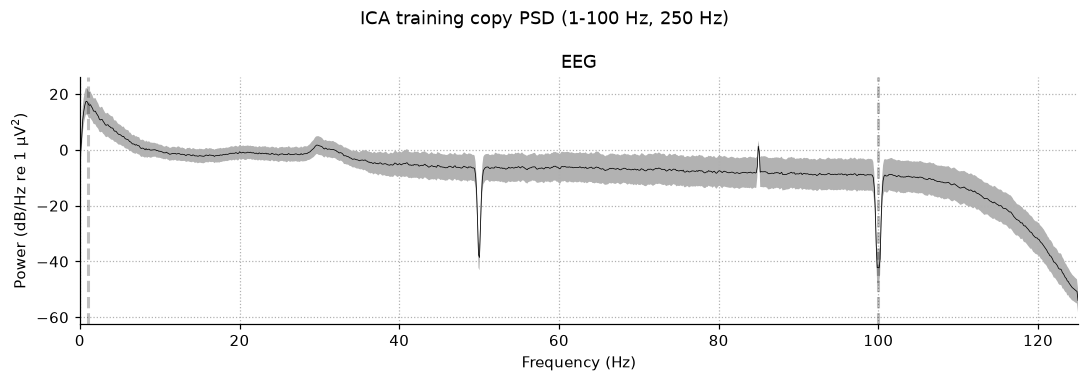

In [6]:
ica_copy = pp.prepare_ica_copy(raw_ref, bad_channels)
print(f"ICA copy sfreq: {ica_copy.info['sfreq']} Hz")
print(f"ICA copy duration: {ica_copy.times[-1]:.1f} s")
print(f"Data rank (estimate): {mne.compute_rank(ica_copy, rank=None)['eeg']}")

fig = ica_copy.compute_psd(fmax=125, n_fft=2048, verbose="ERROR").plot(
    average=True, show=False,
)
fig.suptitle("ICA training copy PSD (1-100 Hz, 250 Hz)")
plt.tight_layout()
plt.show()

## 6. Fit Picard ICA (with disk cache)

Fitting ICA on the training copy takes several minutes. We cache the
fitted decomposition to disk so re-runs of this notebook are fast — only
the very first execution pays the fitting cost.

`ICA_N_COMPONENTS=0.999999` retains the full data rank (62 components for
63 channels after average reference). MNE's internal default when
`n_components=None` is also 0.999999; the earlier 0.99 setting truncated
36 of 62 dimensions and starved the decomposition.

In [7]:
ica_cache = CACHE / f"{SUBJECT}_ica.fif"

if ica_cache.exists():
    print(f"Loading cached ICA from {ica_cache}")
    ica = mne.preprocessing.read_ica(ica_cache)
else:
    print("Fitting ICA... this takes a few minutes on the first run.")
    ica = pp.fit_ica(ica_copy)
    ica.save(ica_cache, overwrite=True, verbose="ERROR")
    print(f"Saved -> {ica_cache}")

print(f"n_components: {ica.n_components_}")
print(f"method: {ica.method}")
print(f"fit_params: {ica.fit_params}")

Fitting ICA... this takes a few minutes on the first run.
Saved -> D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-04\cache\sub-04_ica.fif
n_components: 62
method: picard
fit_params: {'extended': True, 'ortho': False, 'max_iter': 500}


## 7. ICLabel classification

ICLabel assigns each component a probability distribution over seven
categories: brain, muscle, eye, heart, line noise, channel noise, other.
We reject any component whose highest-probability non-brain class has
probability ≥ 0.8.

Expected breakdown on clean task EEG (EEGLAB benchmark; Pion-Tonachini
et al. 2019): roughly 50–55% brain, ~19% muscle, ~3% eye, rest other.
Deviations from this are informative, not automatically errors.

In [8]:
labels_cache = CACHE / f"{SUBJECT}_iclabel.json"

if labels_cache.exists():
    print(f"Loading cached ICLabel from {labels_cache}")
    with open(labels_cache) as f:
        cache = json.load(f)
    ica_labels = cache["labels"]
    ica_probas = cache["probas"]
    exclude = cache["exclude"]
else:
    print("Running ICLabel...")
    labels_dict, exclude = pp.classify_ica_components(ica, ica_copy)
    ica_labels = labels_dict["labels"]
    ica_probas = labels_dict["y_pred_proba"].tolist()
    with open(labels_cache, "w") as f:
        json.dump({"labels": ica_labels, "probas": ica_probas,
                   "exclude": exclude}, f)
    print(f"Saved -> {labels_cache}")

ica.exclude = list(exclude)

from collections import Counter
counts = Counter(ica_labels)
total = len(ica_labels)
print(f"\nICLabel category counts ({total} components total):")
for cat, n in counts.most_common():
    print(f"  {cat:15s}: {n:3d}  ({100 * n / total:.1f}%)")
print(f"\nComponents to exclude: {len(exclude)}")
print(f"Excluded indices: {exclude}")

Running ICLabel...
Saved -> D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-04\cache\sub-04_iclabel.json

ICLabel category counts (62 components total):
  muscle artifact:  26  (41.9%)
  brain          :  17  (27.4%)
  other          :   7  (11.3%)
  eye blink      :   5  (8.1%)
  line noise     :   5  (8.1%)
  channel noise  :   2  (3.2%)

Components to exclude: 20
Excluded indices: [0, 1, 2, 4, 5, 7, 8, 9, 12, 14, 21, 23, 28, 31, 33, 37, 40, 42, 43, 44]


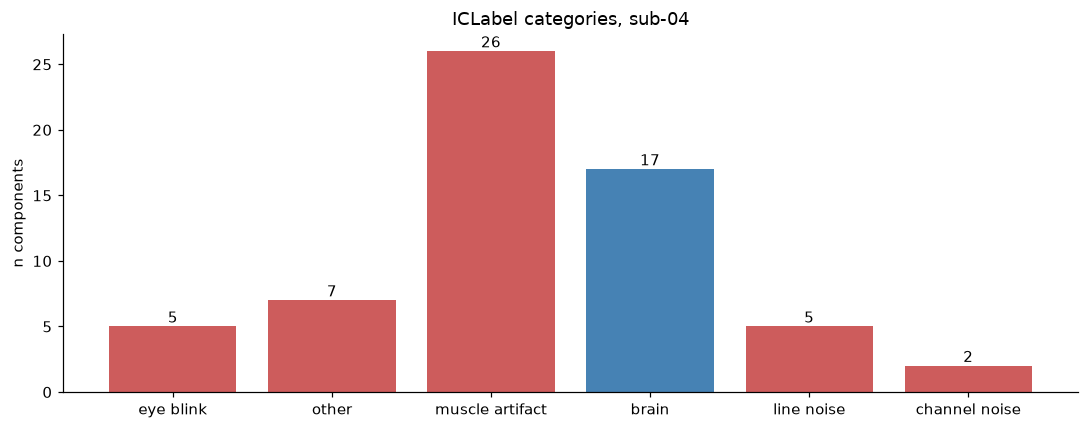

Brain: 17 / 62 = 27.4% (EEGLAB benchmark: ~50-55%)


In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
cats = list(counts.keys())
vals = [counts[c] for c in cats]
colors = ["steelblue" if c == "brain" else "indianred" for c in cats]
ax.bar(cats, vals, color=colors)
ax.set_title(f"ICLabel categories, {SUBJECT}")
ax.set_ylabel("n components")
for i, v in enumerate(vals):
    ax.text(i, v + 0.3, str(v), ha="center")
plt.tight_layout()
plt.show()

print(f"Brain: {counts.get('brain', 0)} / {total} = "
      f"{100 * counts.get('brain', 0) / total:.1f}% "
      f"(EEGLAB benchmark: ~50-55%)")

## 8. Component topographies

The map below shows every component's scalp topography, with the
ICLabel prediction and probability in the title. Components marked in
red are those selected for exclusion.

Read this as a spot-check: do the eye components look eye-like
(frontal, steep gradient)? Do the muscle components look muscle-like
(temporal/occipital, focal, high-frequency)? Do the brain components
look brain-like (smooth, broad, dipolar)?

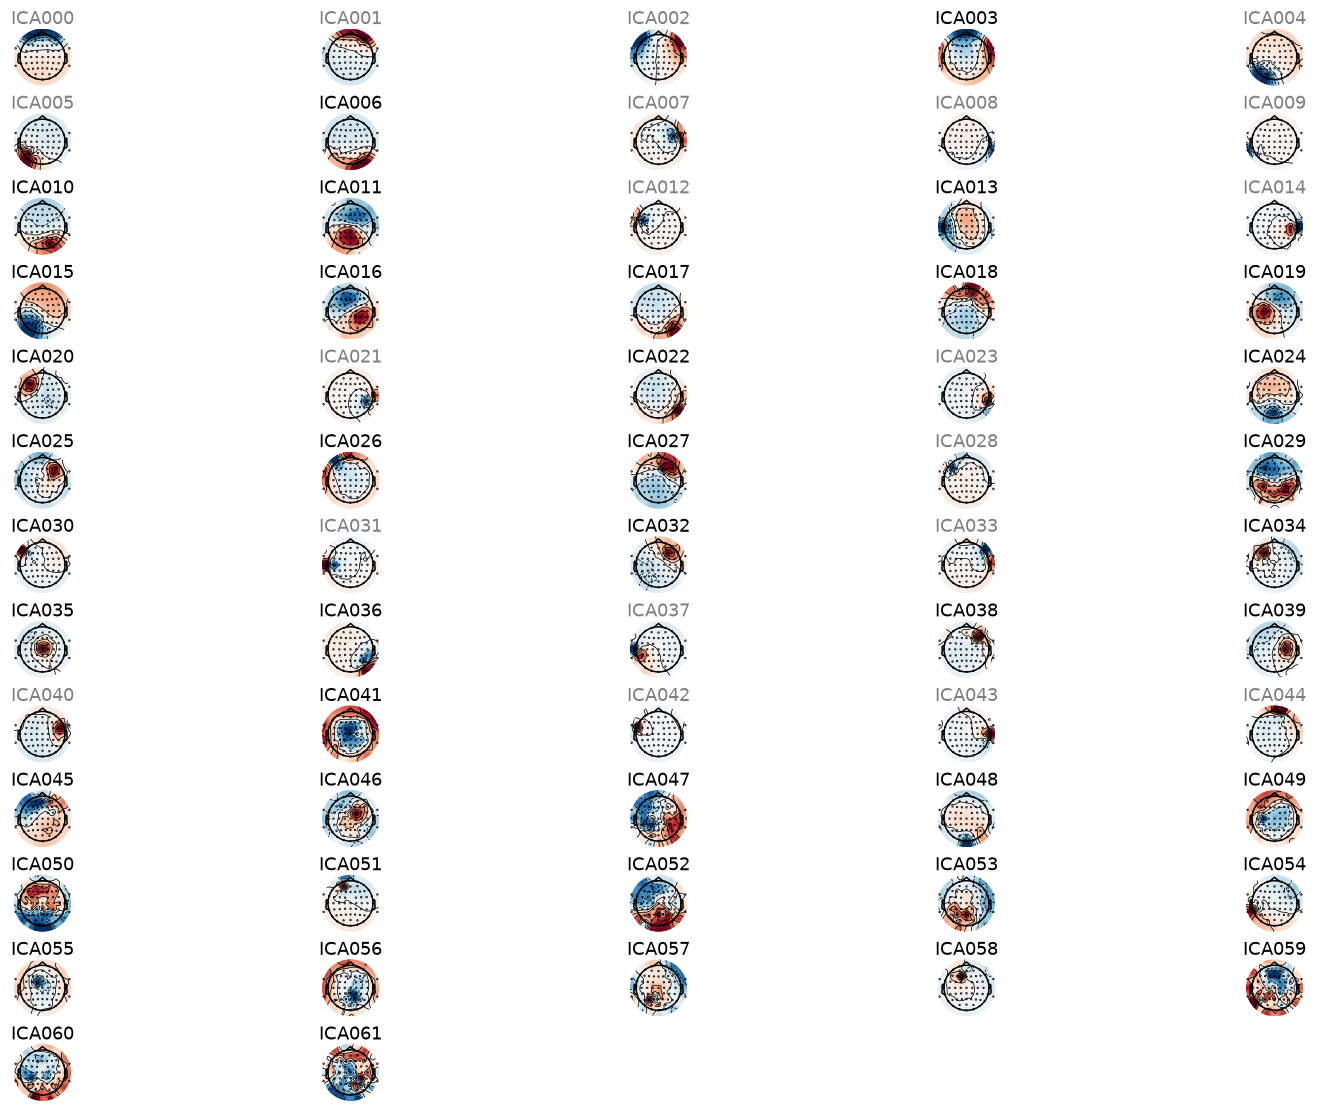

Excluded components: [0, 1, 2, 4, 5, 7, 8, 9, 12, 14, 21, 23, 28, 31, 33, 37, 40, 42, 43, 44]
In the plotted topographies, excluded components should be visually
consistent with the artifact class ICLabel assigned to them.


In [10]:
# plot_components is verbose; suppress its logging and render the figure.
import logging
logging.getLogger("mne").setLevel(logging.ERROR)

figs = ica.plot_components(
    picks=list(range(ica.n_components_)),
    show=False,
    title=f"{SUBJECT} — ICA components ({ica.n_components_} total)",
)
if isinstance(figs, list):
    for fig in figs:
        fig.set_size_inches(14, 10)
        plt.show()
else:
    figs.set_size_inches(14, 10)
    plt.show()

print(f"Excluded components: {sorted(ica.exclude)}")
print("In the plotted topographies, excluded components should be visually")
print("consistent with the artifact class ICLabel assigned to them.")

## 9. Apply ICA and inspect before/after

We apply the ICA solution to the full-rate analysis copy and compare:

- PSD before vs. after (muscle components carry high-frequency energy)
- Amplitude distribution before vs. after (eye components are large)

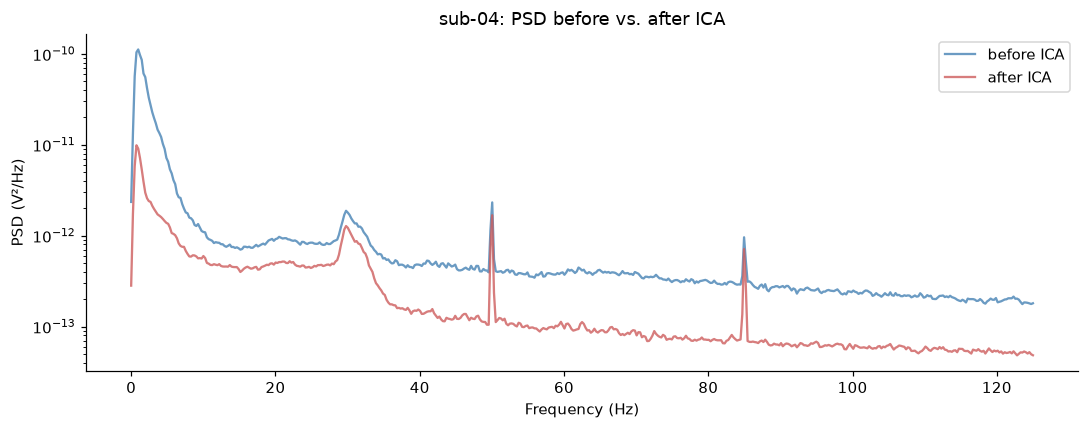

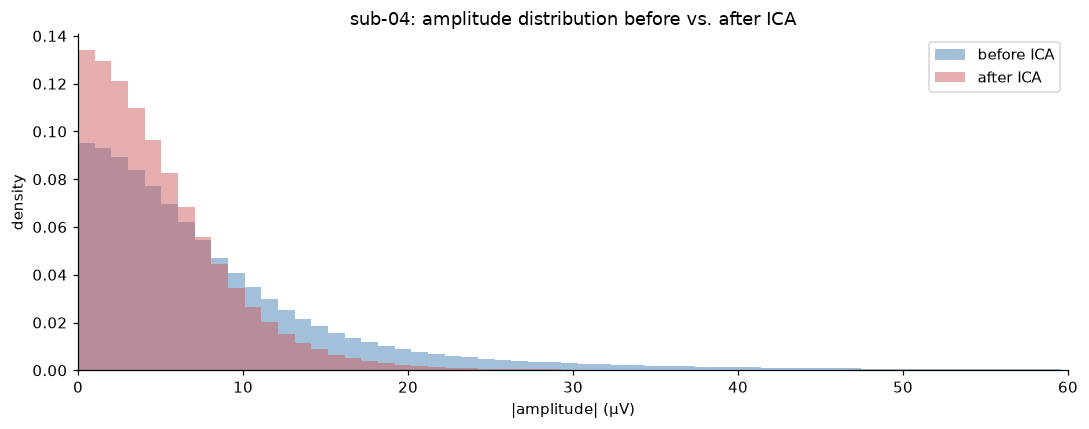

P95 |amplitude| before ICA: 27.83 µV
P95 |amplitude| after ICA:  13.26 µV


In [11]:
raw_before = raw_ref.copy()
raw_after = pp.apply_ica(raw_ref.copy(), ica)

psd_before = raw_before.compute_psd(fmax=125, n_fft=4096, verbose="ERROR")
psd_after = raw_after.compute_psd(fmax=125, n_fft=4096, verbose="ERROR")

fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(psd_before.freqs, psd_before.get_data().mean(axis=0),
            label="before ICA", color="steelblue", alpha=0.8)
ax.semilogy(psd_after.freqs, psd_after.get_data().mean(axis=0),
            label="after ICA", color="indianred", alpha=0.8)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("PSD (V²/Hz)")
ax.set_title(f"{SUBJECT}: PSD before vs. after ICA")
ax.legend()
plt.tight_layout()
plt.show()

amp_before = np.abs(raw_before.get_data() * 1e6)
amp_after = np.abs(raw_after.get_data() * 1e6)

fig, ax = plt.subplots(figsize=(10, 4))
bins = np.linspace(0, 100, 100)
ax.hist(amp_before.flatten(), bins=bins, alpha=0.5, density=True,
        label="before ICA", color="steelblue")
ax.hist(amp_after.flatten(), bins=bins, alpha=0.5, density=True,
        label="after ICA", color="indianred")
ax.set_xlabel("|amplitude| (µV)")
ax.set_ylabel("density")
ax.set_title(f"{SUBJECT}: amplitude distribution before vs. after ICA")
ax.set_xlim(0, 60)
ax.legend()
plt.tight_layout()
plt.show()

print(f"P95 |amplitude| before ICA: {np.percentile(amp_before, 95):.2f} µV")
print(f"P95 |amplitude| after ICA:  {np.percentile(amp_after, 95):.2f} µV")

## 10. Low-pass, downsample, final QC

We apply a 45 Hz zero-phase FIR low-pass, then downsample to 250 Hz. MNE's
`resample` applies an anti-aliasing filter internally, so frequencies above
the new Nyquist (125 Hz) cannot fold back into the lower band.

Final sfreq:   250.0 Hz
Final n_ch:    63
Final duration:1196.5 s


C:\Users\DELL\AppData\Local\Temp\ipykernel_8188\654228745.py:13: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


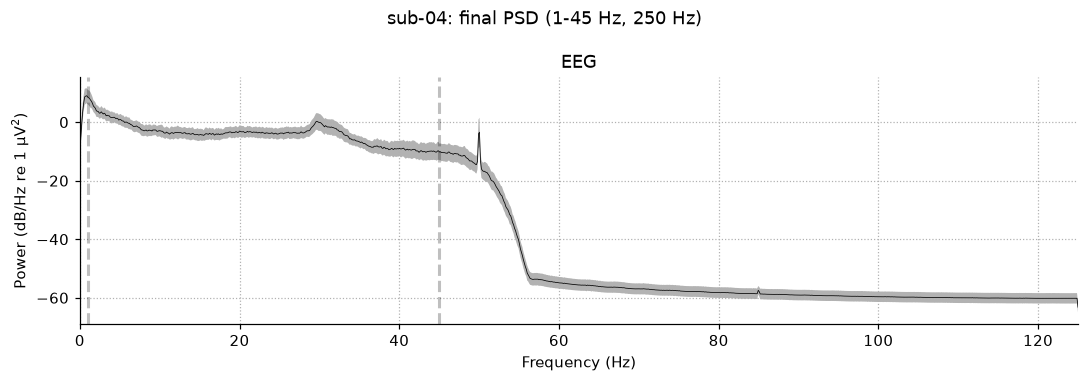

: 

In [ ]:
raw_final = pp.lowpass(raw_after.copy())
raw_final = pp.interpolate_bad_channels(raw_final)
raw_final = pp.downsample(raw_final)

print(f"Final sfreq:   {raw_final.info['sfreq']} Hz")
print(f"Final n_ch:    {len(raw_final.ch_names)}")
print(f"Final duration:{raw_final.times[-1]:.1f} s")

fig = raw_final.compute_psd(fmax=125, n_fft=2048, verbose="ERROR").plot(
    average=True, show=False,
)
fig.suptitle(f"{SUBJECT}: final PSD (1-45 Hz, 250 Hz)")
plt.tight_layout()
plt.show()

## 11. End-to-end pipeline via `preprocess_subject`

The notebook so far ran each stage explicitly. The packaged function
`preprocess_subject` chains them together for batch processing. Here we
just call it once to confirm the result matches the manual walkthrough.

In [13]:
raw_e2e, qc = pp.preprocess_subject(SUBJECT, save=True, overwrite=True)
print("QC dict:")
for k, v in qc.items():
    print(f"  {k}: {v}")

QC dict:
  n_channels: 63
  n_bad_channels: 0
  n_ica_components: 62
  n_excluded_components: 22
  sfreq_hz: 250.0
  duration_s: 1196.548
  p95_amplitude_uv: 10.78700163033822


## Interpretation

### What this single-subject walkthrough revealed

Running the pipeline on `sub-04` produced a clean-looking decomposition —
rank 62 after average reference, 62 ICA components, low-frequency power
suppressed, high-frequency power attenuated after ICA — but an ICLabel
category distribution that did **not** match published benchmarks:

| Category      | sub-04 | EEGLAB benchmark |
|---------------|--------|------------------|
| Brain         | 27.4%  | ~50–55%          |
| Muscle        | 41.9%  | ~13–35%          |
| Line noise    | 8.1%   | ~3–10%           |

Brain at 27.4% is well below the benchmark; muscle at 41.9% is at the high
end. Line noise at 19.4% in the **first** run of this notebook (before the
notch-filter change described below) was the most anomalous figure, and
motivated the 50/100 Hz notch that is now part of `prepare_ica_copy`.

After notching, line-noise components dropped from 12 to 5 (19.4% → 8.1%).
Brain did not rise — it stayed at 17 components, and the freed dimensions
were reclassified as muscle. Interpretation: line noise was masking muscle
components, not consuming dimensions that would otherwise have been brain.

### Whether the pattern is subject-specific

The notebook alone cannot answer this: `sub-04` is one participant, and
either (a) that participant has an unusual EEG profile, or (b) the pattern
is systematic across the cohort. To distinguish, `scripts/subset_qc_summary.py`
runs the same pipeline on `sub-05` and `sub-10` and records the ICLabel
distributions to `results/metrics/subset_qc_iclabel.json`.

| Category       | sub-04 | sub-05 | sub-10 |
|----------------|--------|--------|--------|
| Brain          | 27.4%  | 17.7%  | 24.2%  |
| Muscle         | 41.9%  | 29.0%  | 30.6%  |
| Channel noise  | 3.2%   | 12.9%  | 11.3%  |

Brain is low across all three subjects (17.7–27.4%), which rules out a
subject-specific explanation. Channel noise is elevated in `sub-05` and
`sub-10` relative to `sub-04`.

### Follow-up on channel noise

Visual inspection of the channel-noise components in `sub-05` and `sub-10`
showed that most had low ICLabel confidence (predicted-class probability
< 0.8) and non-focal topographies — consistent with misclassification of
ambiguous components rather than true single-electrode defects. A small
number did show focal single-electrode topographies (FT8 in `sub-05`;
P1, CP3, C2 in `sub-10`), suggesting subtle bad channels that the
variance-based detector did not flag.

### Decision

The pipeline is frozen as implemented. The elevated muscle fraction and
reduced brain fraction are attributed to (a) task-related muscle activity
(the Sternberg task uses verbal stimuli, plausibly inducing subvocalisation)
and (b) the fact that published ICLabel benchmarks come from curated
datasets with stricter acquisition and preprocessing than a single-subject
validation run. See the README's **Key Design Decisions** and
**What This Project Does Not Claim** sections for the corresponding
methodological discussion and limitations.

### Cohort-level QC

The single-subject walkthrough above established that the pipeline behaves
as intended on `sub-04`. To verify this across a broader sample and to
produce the artifacts that feed the downstream state model, the pipeline
was then applied to the eight subjects in `config.DEV_SUBJECTS` via
`scripts/batch_preprocess.py`, writing a QC table to
`results/metrics/batch_preprocessing_qc.csv`.

The batch run confirmed two things that a single subject could not:
first, the variance-based bad-channel detector does fire when
non-negligible variance outliers are present (`sub-17`, `sub-34`, `sub-45`
had 4, 1, and 2 flagged channels respectively), so the earlier "zero bad
channels" pattern on `sub-04`, `sub-05`, and `sub-10` reflects genuinely
clean channel data rather than a broken detector; second, ICA retained the
full referenced rank in every subject, confirming that the
`n_components=0.999999` choice is not silently truncating on any subject in
the subset.

The eight-subject QC table is the artifact passed to the modeling stage.
The derivatives under `data/derivatives/<subject>/` are what
`src/eeg_state/model.py` will consume for TDE-HMM fitting.